# Fixed Priority Analysis (100k Window)

## Libraries and Priority Orders

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

workloads = ["chirper", "mcf", "omnetpp", "tomcat", "tpcc"]
orders = ["IDP", "IPD", "DIP", "DPI", "PID", "PDI"]
# I = Instruction, D = Data, P = PTE. Highest priority comes first.

## Workload Data

In [20]:
data = {}

for workload in workloads:
    data[workload] = {}
    for policy in ["LRU"] + orders:
        data[workload][policy] = pd.read_csv(f"../data/{workload}_{policy}_100k.csv")


## Overall IPC and Gain over LRU

In [21]:
overall_ipc = pd.DataFrame(index=workloads, columns=["LRU"] + orders, dtype=float)

for workload in workloads:
    for policy in ["LRU"] + orders:
        run = data[workload][policy]
        overall_ipc.loc[workload, policy] = run["instructions"].sum() / run["cycles"].sum()

ipc_gain = overall_ipc[orders].div(overall_ipc["LRU"], axis=0).sub(1) * 100
ipc_gain.round(3)

,IDP,IPD,DIP,DPI,PID,PDI
chirper,2.546,2.536,-2.836,-2.867,2.732,-1.559
mcf,-22.090,0.030,-22.089,-22.089,0.030,0.030
omnetpp,-0.475,3.016,-0.624,-0.623,3.016,2.899
tomcat,1.487,1.543,-4.787,-4.810,1.703,-4.268
tpcc,-0.162,-0.146,-6.545,-7.814,-0.142,-7.796


## Overall IPC Gain by Priority

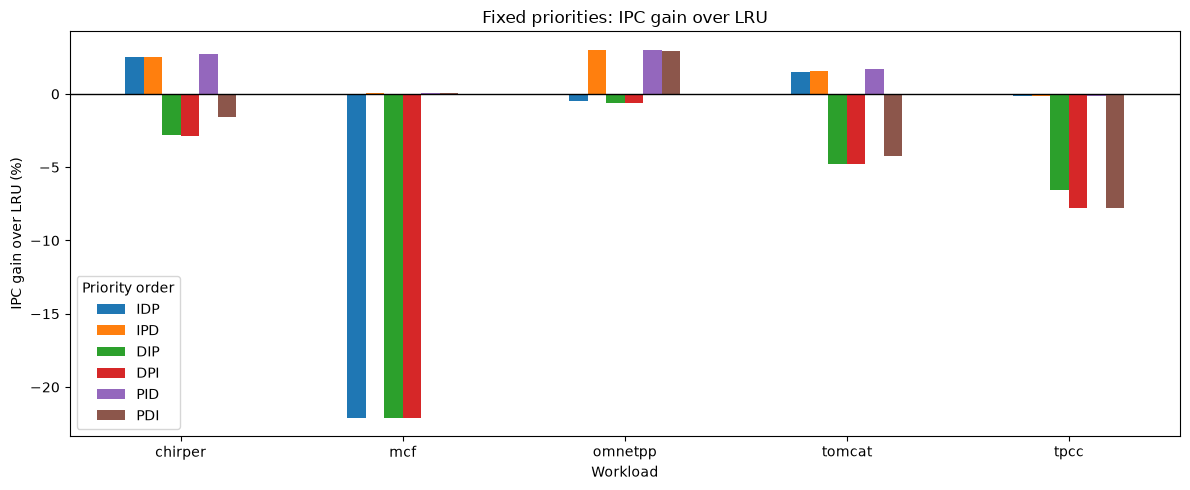

In [22]:
ipc_gain.plot.bar(figsize=(12, 5))

plt.axhline(0, color="black", linewidth=1)
plt.title("Fixed priorities: IPC gain over LRU")
plt.xlabel("Workload")
plt.ylabel("IPC gain over LRU (%)")
plt.xticks(rotation=0)
plt.legend(title="Priority order")
plt.tight_layout()
plt.savefig("../results/fixed_100k_ipc_gain.png", dpi=300)
plt.show()

## Best Fixed Orders over the Whole Run

In [23]:
best_fixed = []

for workload in workloads:
    gains = ipc_gain.loc[workload]
    winners = gains[gains == gains.max()].index.tolist()
    best_fixed.append({
        "workload": workload,
        "best_fixed_orders": ", ".join(winners),
        "gain_over_LRU_percent": gains.max(),
        "LRU_beats_all_fixed": gains.max() < 0
    })

pd.DataFrame(best_fixed).set_index("workload")

,best_fixed_orders,gain_over_LRU_percent,LRU_beats_all_fixed
workload,,,
chirper,PID,2.731993,False
mcf,"IPD, PID",0.029980,False
omnetpp,"IPD, PID",3.016448,False
tomcat,PID,1.702952,False
tpcc,PID,-0.142409,True


## Class-wise L2 Misses

In [24]:
miss_comparison = []

for workload in workloads:
    baseline = data[workload]["LRU"]
    for policy in ["LRU"] + orders:
        run = data[workload][policy]
        instruction = run["instruction_misses"].sum()
        demand_data = run["data_misses"].sum()
        pte = run["pte_misses"].sum()
        baseline_misses = baseline[["instruction_misses", "data_misses", "pte_misses"]].sum().sum()
        miss_comparison.append({
            "workload": workload,
            "policy": policy,
            "instruction_misses": instruction,
            "data_misses": demand_data,
            "pte_misses": pte,
            "total_misses": instruction + demand_data + pte,
            "miss_change_from_LRU": instruction + demand_data + pte - baseline_misses,
            "ipc_gain_percent": 0 if policy == "LRU" else ipc_gain.loc[workload, policy]
        })

miss_comparison = pd.DataFrame(miss_comparison)
miss_comparison.set_index(["workload", "policy"])

instruction_misses  data_misses  pte_misses  total_misses  \
workload policy                                                              
chirper  LRU                  57703        71862        7626        137191   
         IDP                  25667       149106       19149        193922   
         IPD                  25668       155992       16308        197968   
         DIP                 170031        55761       19952        245744   
         DPI                 171503        55762       19497        246762   
         PID                  33025       154816        2198        190039   
         PDI                 170380        59291        2198        231869   
mcf      LRU                      0       260040         642        260682   
         IDP                      0       259207      227358        486565   
         IPD                      0       260216         508        260724   
         DIP                      0       259205      227358        486563   
         DPI                      0       259205      227358        486563   
         PID                      0       260216         508        260724   
         PDI                      0       260210         508        260718   
omnetpp  LRU                    315       115291       17248        132854   
         IDP                     61       112156       42624        154841   
         IPD                     61       125434        3794        129289   
         DIP                   4363       111542       42712        158617   
         DPI                   4442       111543       42640        158625   
         PID                     61       125434        3794        129289   
         PDI                   4200       123899        3794        131893   
tomcat   LRU                  48608        49443        4488        102539   
         IDP                  22227       108994       11016        142237   
         IPD                  22308       114351        8992        145651   
         DIP                 139320        32373       11363        183056   
         DPI                 140416        32372       10909        183697   
         PID                  26974       113850        1812        142636   
         PDI                 139862        33577        1812        175251   
tpcc     LRU                   8130        14252         365         22747   
         IDP                   7240        19170        1120         27530   
         IPD                   7240        20437         252         27929   
         DIP                 110682        13552        1365        125599   
         DPI                 133495        13552         635        147682   
         PID                   7243        20435         233         27911   
         PDI                 133450        13555         233        147238   

                 miss_change_from_LRU  ipc_gain_percent  
workload policy                                          
chirper  LRU                        0          0.000000  
         IDP                    56731          2.545702  
         IPD                    60777          2.536287  
         DIP                   108553         -2.836303  
         DPI                   109571         -2.866698  
         PID                    52848          2.731993  
         PDI                    94678         -1.558868  
mcf      LRU                        0          0.000000  
         IDP                   225883        -22.090102  
         IPD                       42          0.029980  
         DIP                   225881        -22.089378  
         DPI                   225881        -22.089378  
         PID                       42          0.029980  
         PDI                       36          0.029892  
omnetpp  LRU                        0          0.000000  
         IDP                    21987         -0.474513  
         IPD                    -3565          3.016448  
         DIP                

## Phase-wise IPC Gain over LRU

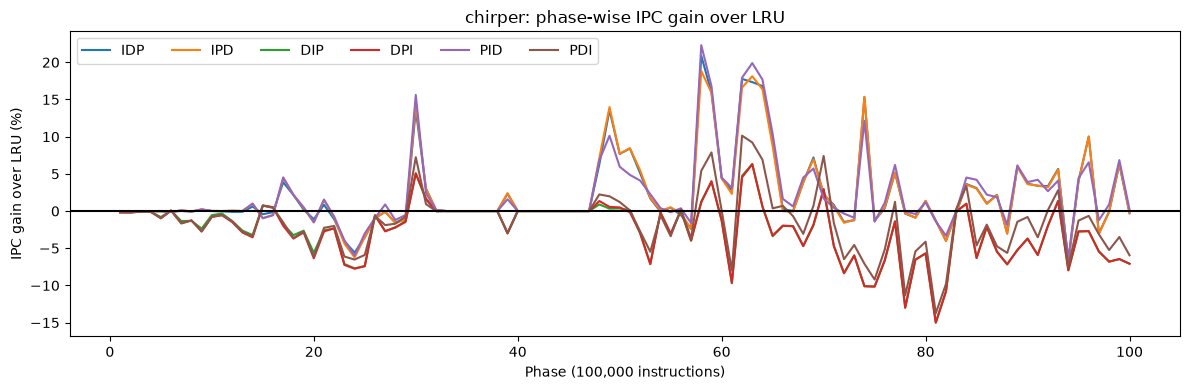

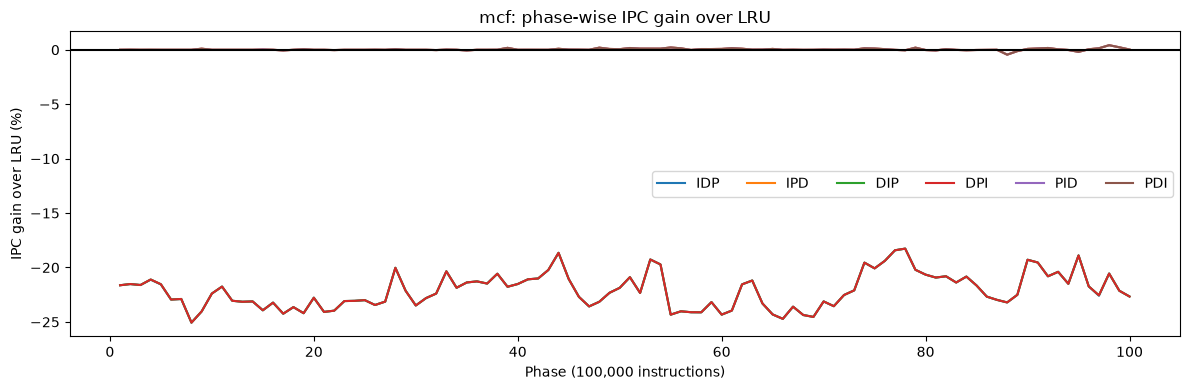

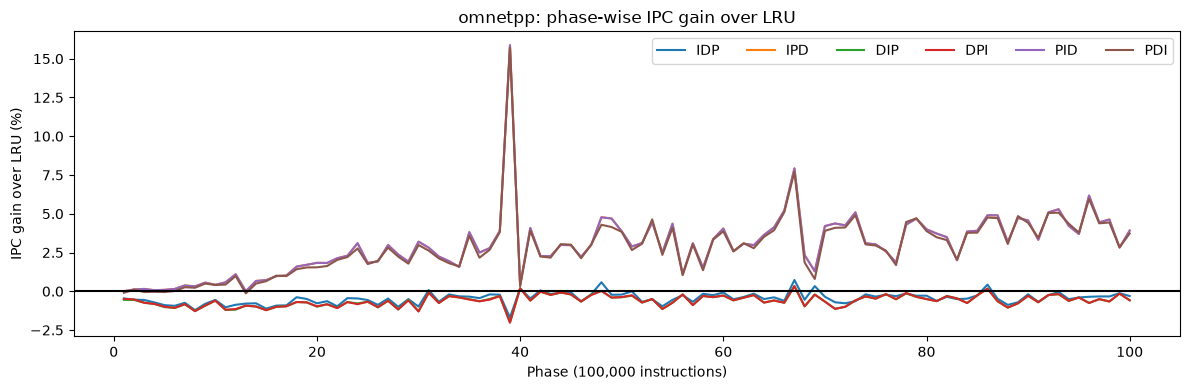

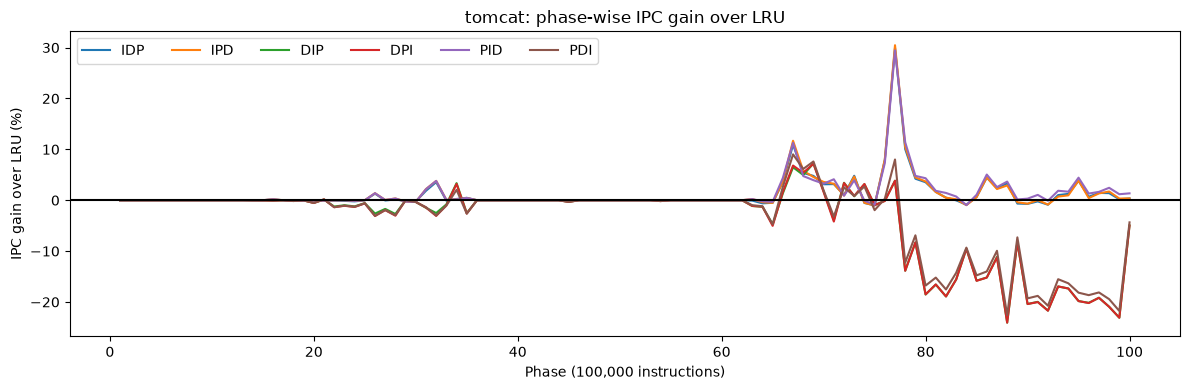

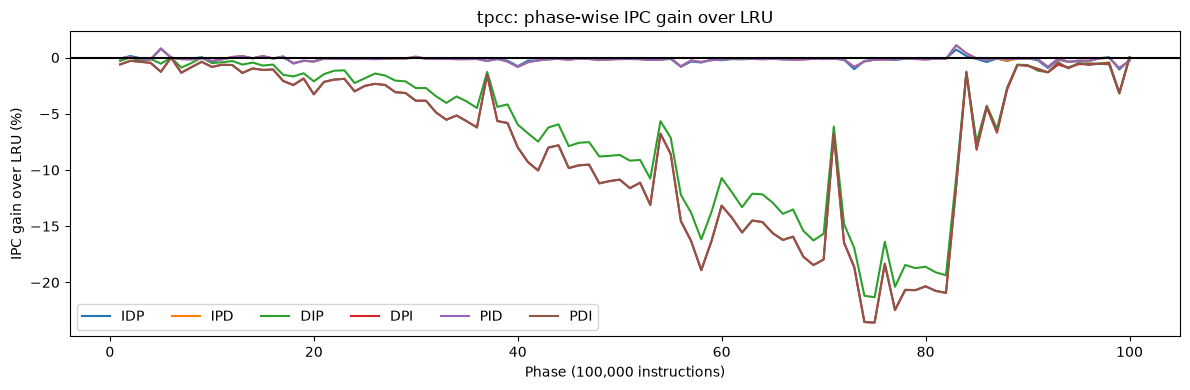

In [25]:
phase_cycles = {}

for workload in workloads:
    baseline = data[workload]["LRU"].set_index("phase")
    phase_cycles[workload] = pd.DataFrame(index=baseline.index)

    plt.figure(figsize=(12, 4))

    for order in orders:
        run = data[workload][order].set_index("phase")
        phase_cycles[workload][order] = run["cycles"]

        gain = (baseline["cycles"] / run["cycles"] - 1) * 100
        plt.plot(run.index, gain, label=order)

    plt.axhline(0, color="black")
    plt.title(f"{workload}: phase-wise IPC gain over LRU")
    plt.xlabel("Phase (100,000 instructions)")
    plt.ylabel("IPC gain over LRU (%)")
    plt.legend(ncol=6)
    plt.tight_layout()
    plt.savefig(f"../results/{workload}_fixed_100k_phase_gain.png", dpi=300)
    plt.show()

## Highest-IPC Phase Counts (Each Tied Order Receives +1)

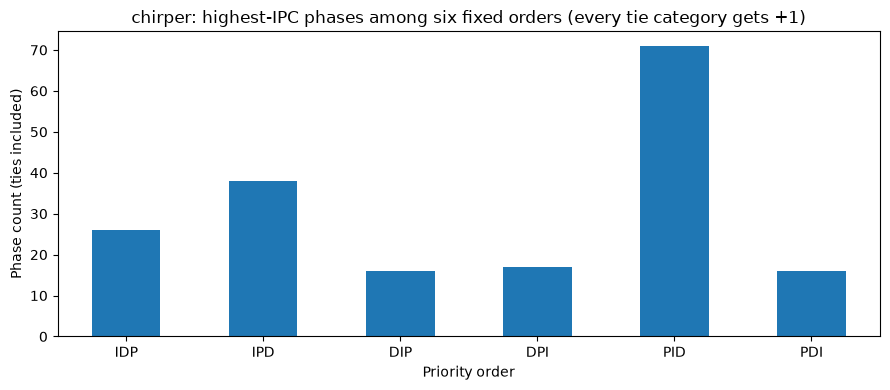

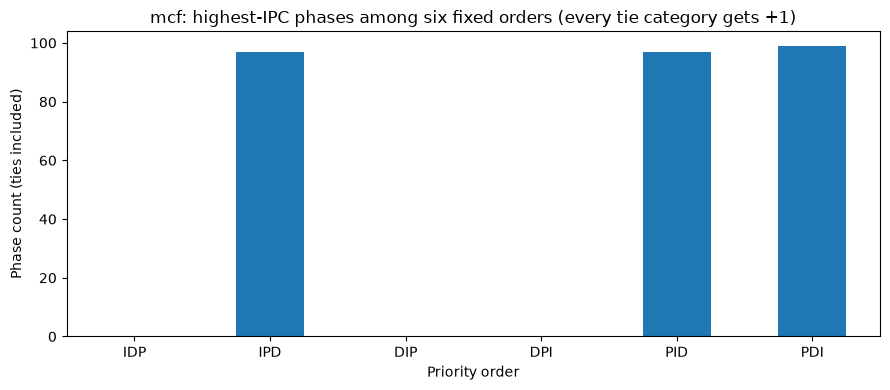

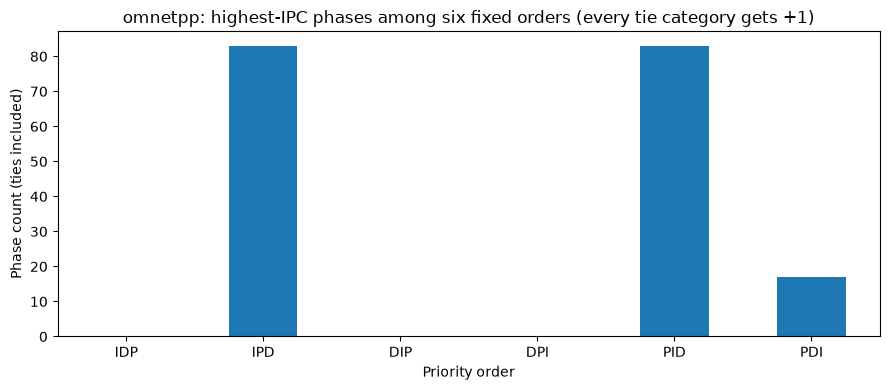

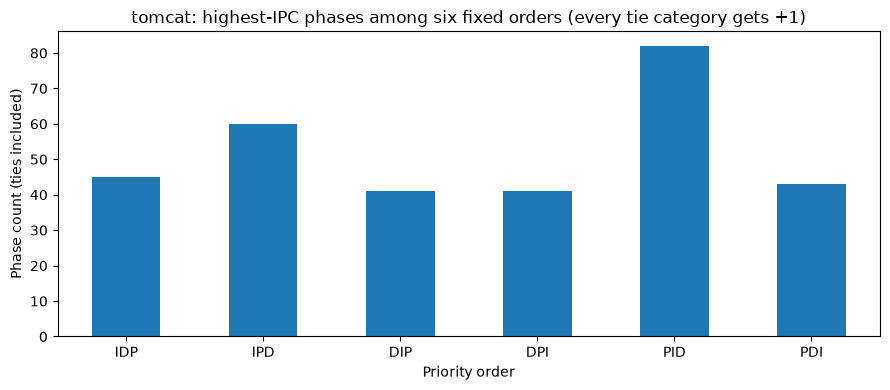

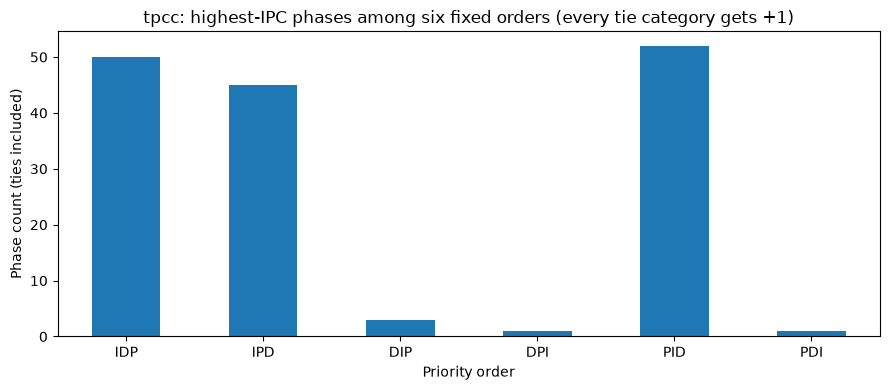

,IDP,IPD,DIP,DPI,PID,PDI
chirper,26,38,16,17,71,16
mcf,0,97,0,0,97,99
omnetpp,0,83,0,0,83,17
tomcat,45,60,41,41,82,43
tpcc,50,45,3,1,52,1


,single_winner_phases,partially_tied_phases,all_six_tied_phases
workload,,,
chirper,73,13,14
mcf,3,97,0
omnetpp,17,83,0
tomcat,43,19,38
tpcc,55,45,0


In [26]:
phase_winners = {}
phase_counts = pd.DataFrame(index=workloads, columns=orders, dtype=int)
tie_counts = []

for workload in workloads:
    cycles = phase_cycles[workload]
    # Equal instructions: minimum cycles means maximum IPC. Preserve exact ties.
    winners = cycles.eq(cycles.min(axis=1), axis=0)
    phase_winners[workload] = winners
    phase_counts.loc[workload] = winners.sum()
    winner_count = winners.sum(axis=1)
    tie_counts.append({
        "workload": workload,
        "single_winner_phases": (winner_count == 1).sum(),
        "partially_tied_phases": ((winner_count > 1) & (winner_count < 6)).sum(),
        "all_six_tied_phases": (winner_count == 6).sum()
    })

    winners.sum().plot.bar(figsize=(9, 4))
    plt.title(f"{workload}: highest-IPC phases among six fixed orders (every tie category gets +1)")
    plt.xlabel("Priority order")
    plt.ylabel("Phase count (ties included)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f"../results/{workload}_fixed_100k_winner_counts.png", dpi=300)
    plt.show()

display(phase_counts.astype(int))
display(pd.DataFrame(tie_counts).set_index("workload"))